In [1]:
packages <- c(
  "arrow", "data.table", "ggplot2", "lubridate",
  "foreach", "doParallel", "microbenchmark"
)

for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p, repos = "https://cloud.r-project.org")
  }
}

library(arrow)
library(data.table)
library(ggplot2)
library(lubridate)
library(foreach)
library(doParallel)
library(microbenchmark)

cat("All packages installed and loaded successfully!\n")


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘assertthat’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘iterators’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘arrow’


The following object is masked from ‘package:utils’:

    timestamp



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%



Attaching package: ‘lubridate’


The following objects are masked from ‘package:data.table’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following object is masked from ‘package:arrow’:

    duration


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


Loading required packag

All packages installed and loaded successfully!


In [2]:

taxi_url <- "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
zone_url <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

taxi_file <- "/content/yellow_tripdata_2024-01.parquet"
zone_file <- "/content/taxi_zone_lookup.csv"

if (!file.exists(taxi_file)) {
  download.file(taxi_url, taxi_file, mode = "wb")
}

if (!file.exists(zone_file)) {
  download.file(zone_url, zone_file, mode = "wb")
}

cat("Taxi dataset and zone lookup are ready.\n")


Taxi dataset and zone lookup are ready.


In [3]:

trips <- as.data.table(read_parquet(taxi_file))
zones <- fread(zone_file)

cat("Dataset dimensions:\n")
print(dim(trips))

cat("\nColumn names:\n")
print(names(trips))

cat("\nStructure:\n")
str(trips)

cat("\nSummary statistics:\n")
print(summary(trips))

cat("\nMissing values per column:\n")
print(colSums(is.na(trips)))

cat("\nDuplicate rows:\n")
print(sum(duplicated(trips)))


Dataset dimensions:
[1] 2964624      19

Column names:
 [1] "VendorID"              "tpep_pickup_datetime"  "tpep_dropoff_datetime"
 [4] "passenger_count"       "trip_distance"         "RatecodeID"           
 [7] "store_and_fwd_flag"    "PULocationID"          "DOLocationID"         
[10] "payment_type"          "fare_amount"           "extra"                
[13] "mta_tax"               "tip_amount"            "tolls_amount"         
[16] "improvement_surcharge" "total_amount"          "congestion_surcharge" 
[19] "Airport_fee"          

Structure:
Classes ‘data.table’ and 'data.frame':	2964624 obs. of  19 variables:
 $ VendorID             : int  2 1 1 1 1 1 2 1 2 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2024-01-01 00:57:55" "2024-01-01 00:03:00" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2024-01-01 01:17:43" "2024-01-01 00:09:36" ...
 $ passenger_count      : int  1 1 1 1 1 1 2 0 1 1 ...
 $ trip_distance        : num  1.72 1.8 4.7 1.4 0.8 ...
 $ RatecodeID           

In [4]:

required_cols <- c(
  "tpep_pickup_datetime", "tpep_dropoff_datetime",
  "passenger_count", "trip_distance", "PULocationID",
  "DOLocationID", "fare_amount", "tip_amount",
  "tolls_amount", "total_amount", "payment_type"
)

missing_cols <- setdiff(required_cols, names(trips))

if (length(missing_cols) > 0) {
  stop(paste("Missing columns:", paste(missing_cols, collapse = ", ")))
}

trips <- trips[, ..required_cols]
trips <- unique(trips)

trips <- trips[
  !is.na(tpep_pickup_datetime) &
  !is.na(tpep_dropoff_datetime) &
  !is.na(trip_distance) &
  !is.na(fare_amount) &
  !is.na(total_amount) &
  trip_distance > 0 &
  fare_amount >= 0 &
  total_amount >= 0 &
  tpep_dropoff_datetime >= tpep_pickup_datetime
]

cat("Cleaned dataset dimensions:\n")
print(dim(trips))


Cleaned dataset dimensions:
[1] 2870052      11


In [5]:

trips[, pickup_hour := hour(tpep_pickup_datetime)]
trips[, pickup_day := as.Date(tpep_pickup_datetime)]

trips[, pickup_weekday := wday(
  tpep_pickup_datetime,
  label = TRUE,
  abbr = FALSE,
  week_start = 1
)]

trips[, pickup_month := month(
  tpep_pickup_datetime,
  label = TRUE
)]

print(head(trips))


   tpep_pickup_datetime tpep_dropoff_datetime passenger_count trip_distance
                 <POSc>                <POSc>           <int>         <num>
1:  2024-01-01 00:57:55   2024-01-01 01:17:43               1          1.72
2:  2024-01-01 00:03:00   2024-01-01 00:09:36               1          1.80
3:  2024-01-01 00:17:06   2024-01-01 00:35:01               1          4.70
4:  2024-01-01 00:36:38   2024-01-01 00:44:56               1          1.40
5:  2024-01-01 00:46:51   2024-01-01 00:52:57               1          0.80
6:  2024-01-01 00:54:08   2024-01-01 01:26:31               1          4.70
   PULocationID DOLocationID fare_amount tip_amount tolls_amount total_amount
          <int>        <int>       <num>      <num>        <num>        <num>
1:          186           79        17.7       0.00            0        22.70
2:          140          236        10.0       3.75            0        18.75
3:          236           79        23.3       3.00            0        31.30
4:

In [6]:

pickup_zones <- copy(zones)
setnames(
  pickup_zones,
  c("LocationID", "Borough", "Zone"),
  c("PULocationID", "pickup_borough", "pickup_zone")
)

dropoff_zones <- copy(zones)
setnames(
  dropoff_zones,
  c("LocationID", "Borough", "Zone"),
  c("DOLocationID", "dropoff_borough", "dropoff_zone")
)

trips <- merge(
  trips, pickup_zones,
  by = "PULocationID",
  all.x = TRUE,
  sort = FALSE
)

trips <- merge(
  trips, dropoff_zones,
  by = "DOLocationID",
  all.x = TRUE,
  sort = FALSE
)

cat("Zone joins completed.\n")
print(head(trips))


Zone joins completed.
   DOLocationID PULocationID tpep_pickup_datetime tpep_dropoff_datetime
          <int>        <int>               <POSc>                <POSc>
1:           79          186  2024-01-01 00:57:55   2024-01-01 01:17:43
2:          236          140  2024-01-01 00:03:00   2024-01-01 00:09:36
3:           79          236  2024-01-01 00:17:06   2024-01-01 00:35:01
4:          211           79  2024-01-01 00:36:38   2024-01-01 00:44:56
5:          148          211  2024-01-01 00:46:51   2024-01-01 00:52:57
6:          141          148  2024-01-01 00:54:08   2024-01-01 01:26:31
   passenger_count trip_distance fare_amount tip_amount tolls_amount
             <int>         <num>       <num>      <num>        <num>
1:               1          1.72        17.7       0.00            0
2:               1          1.80        10.0       3.75            0
3:               1          4.70        23.3       3.00            0
4:               1          1.40        10.0       2.00  

In [7]:

hourly_demand <- trips[
  , .(total_trips = .N),
  by = pickup_hour
][order(pickup_hour)]

weekday_demand <- trips[
  , .(total_trips = .N),
  by = pickup_weekday
][order(pickup_weekday)]

monthly_demand <- trips[
  , .(total_trips = .N),
  by = pickup_month
]

cat("Trips by hour:\n")
print(hourly_demand)

cat("\nTrips by weekday:\n")
print(weekday_demand)

cat("\nTrips by month:\n")
print(monthly_demand)


Trips by hour:
    pickup_hour total_trips
          <int>       <int>
 1:           0       75249
 2:           1       50488
 3:           2       34973
 4:           3       22948
 5:           4       15285
 6:           5       17495
 7:           6       39415
 8:           7       80871
 9:           8      113505
10:           9      125620
11:          10      135426
12:          11      146747
13:          12      159912
14:          13      165359
15:          14      178029
16:          15      184005
17:          16      184969
18:          17      200310
19:          18      206282
20:          19      178809
21:          20      155557
22:          21      155916
23:          22      138244
24:          23      104638
    pickup_hour total_trips
          <int>       <int>

Trips by weekday:
   pickup_weekday total_trips
            <ord>       <int>
1:         Monday      393307
2:        Tuesday      449170
3:      Wednesday      480860
4:       Thursday      416282
5:

In [8]:

hourly_revenue <- trips[
  , .(
    average_fare = mean(fare_amount, na.rm = TRUE),
    total_revenue = sum(total_amount, na.rm = TRUE)
  ),
  by = pickup_hour
][order(pickup_hour)]

print(hourly_revenue)

cat("\nCorrelation between trip distance and fare:\n")
print(cor(
  trips$trip_distance,
  trips$fare_amount,
  use = "complete.obs"
))


    pickup_hour average_fare total_revenue
          <int>        <num>         <num>
 1:           0     19.69441     2150418.4
 2:           1     17.73309     1307760.1
 3:           2     16.62315      860249.4
 4:           3     18.53003      612886.8
 5:           4     23.43523      496197.0
 6:           5     27.49428      657049.9
 7:           6     22.02659     1188484.7
 8:           7     18.77010     2147044.5
 9:           8     17.83363     2899082.2
10:           9     17.95216     3253683.3
11:          10     18.07318     3529222.8
12:          11     17.62895     3738035.1
13:          12     17.80478     4114393.9
14:          13     18.42224     4382764.3
15:          14     19.27515     4924493.2
16:          15     19.11807     5042400.9
17:          16     19.46236     5504068.7
18:          17     18.12845     5639758.8
19:          18     17.01972     5538539.2
20:          19     17.63792     4947555.8
21:          20     18.05087     4244943.6
22:        

In [9]:

route_summary <- trips[
  !is.na(pickup_zone) & !is.na(dropoff_zone),
  .(
    total_trips = .N,
    total_revenue = sum(total_amount, na.rm = TRUE)
  ),
  by = .(pickup_zone, dropoff_zone)
]

top_routes <- route_summary[
  order(-total_trips)
][1:min(10, .N)]

top_revenue_routes <- route_summary[
  order(-total_revenue)
][1:min(10, .N)]

cat("Top 10 most frequent routes:\n")
print(top_routes)

cat("\nTop 10 highest-revenue routes:\n")
print(top_revenue_routes)


Top 10 most frequent routes:
              pickup_zone          dropoff_zone total_trips total_revenue
                   <char>                <char>       <int>         <num>
 1: Upper East Side South Upper East Side North       21642      340615.5
 2: Upper East Side North Upper East Side South       19199      308728.5
 3: Upper East Side North Upper East Side North       15199      200811.1
 4: Upper East Side South Upper East Side South       14118      195140.5
 5:        Midtown Center Upper East Side South       10139      172958.6
 6:   Lincoln Square East Upper West Side South        8828      132207.8
 7: Upper East Side South        Midtown Center        8718      143645.7
 8:        Midtown Center Upper East Side North        8664      189614.7
 9: Upper West Side South   Lincoln Square East        8544      124589.8
10: Upper West Side South Upper West Side North        8306      114916.2

Top 10 highest-revenue routes:
                  pickup_zone              dropoff_

In [10]:

payment_summary <- trips[
  , .(
    total_trips = .N,
    total_revenue = sum(total_amount, na.rm = TRUE)
  ),
  by = payment_type
][order(-total_trips)]

borough_payment <- trips[
  , .(total_trips = .N),
  by = .(pickup_borough, payment_type)
]

cat("Payment summary:\n")
print(payment_summary)

cat("\nPayment methods across boroughs:\n")
print(borough_payment)


Payment summary:
   payment_type total_trips total_revenue
          <int>       <int>         <num>
1:            1     2298414    64529274.3
2:            2      422866    10089629.3
3:            0      115245     3055259.5
4:            4       22879      572064.6
5:            3       10648      235567.1

Payment methods across boroughs:
    pickup_borough payment_type total_trips
            <char>        <int>       <int>
 1:      Manhattan            2      368861
 2:      Manhattan            1     2072529
 3:         Queens            1      198785
 4:         Queens            2       49857
 5:      Manhattan            4       19261
 6:       Brooklyn            1       14626
 7:       Brooklyn            2        1884
 8:            N/A            2         101
 9:         Queens            4        3353
10:        Unknown            1        7645
11:         Queens            3        1513
12:      Manhattan            3        8914
13:            N/A            1        

In [11]:

set.seed(123)

sample_n <- min(100000L, nrow(trips))
sample_trips <- trips[sample.int(nrow(trips), sample_n)]

# Vectorized implementation
vectorized_analysis <- function(x) {
  mean(x$fare_amount, na.rm = TRUE)
}

# lapply implementation
lapply_analysis <- function(x) {
  lapply(
    split(x$fare_amount, x$pickup_hour),
    mean,
    na.rm = TRUE
  )
}

# apply implementation
apply_analysis <- function(x) {
  m <- cbind(
    fare = x$fare_amount,
    total = x$total_amount
  )
  apply(m, 2, mean, na.rm = TRUE)
}

# data.table implementation
datatable_analysis <- function(x) {
  x[, .(
    average_fare = mean(fare_amount, na.rm = TRUE),
    average_total = mean(total_amount, na.rm = TRUE)
  )]
}

cat("Vectorized result:\n")
print(vectorized_analysis(sample_trips))

cat("\nlapply result:\n")
print(lapply_analysis(sample_trips))

cat("\napply result:\n")
print(apply_analysis(sample_trips))

cat("\ndata.table result:\n")
print(datatable_analysis(sample_trips))


Vectorized result:
[1] 18.46858

lapply result:
$`0`
[1] 19.37837

$`1`
[1] 18.27099

$`2`
[1] 16.55855

$`3`
[1] 18.71004

$`4`
[1] 22.87826

$`5`
[1] 28.04773

$`6`
[1] 22.29502

$`7`
[1] 19.07141

$`8`
[1] 17.44798

$`9`
[1] 17.62811

$`10`
[1] 18.29216

$`11`
[1] 17.57491

$`12`
[1] 17.68502

$`13`
[1] 18.28019

$`14`
[1] 18.97459

$`15`
[1] 19.42338

$`16`
[1] 19.62581

$`17`
[1] 18.12132

$`18`
[1] 17.23775

$`19`
[1] 17.94455

$`20`
[1] 17.77995

$`21`
[1] 17.95528

$`22`
[1] 18.79521

$`23`
[1] 20.15568


apply result:
    fare    total 
18.46858 27.31513 

data.table result:
   average_fare average_total
          <num>         <num>
1:     18.46858      27.31513


In [12]:

benchmark_results <- microbenchmark(
  Vectorized = vectorized_analysis(sample_trips),
  lapply = lapply_analysis(sample_trips),
  apply = apply_analysis(sample_trips),
  data_table = datatable_analysis(sample_trips),
  times = 5L
)

print(benchmark_results)

benchmark_summary <- as.data.table(
  summary(benchmark_results)
)

print(benchmark_summary)


Unit: microseconds
       expr      min       lq     mean   median       uq      max neval
 Vectorized  722.271  733.907 1066.073  747.801  782.420 2343.967     5
     lapply 4200.181 4316.735 5015.445 4619.996 5347.099 6593.212     5
      apply 3164.039 3230.347 3829.436 3424.319 3536.289 5792.188     5
 data_table 2517.197 2533.288 3222.670 2534.587 2725.276 5803.003     5
         expr      min       lq     mean   median       uq      max neval
       <fctr>    <num>    <num>    <num>    <num>    <num>    <num> <num>
1: Vectorized  722.271  733.907 1066.073  747.801  782.420 2343.967     5
2:     lapply 4200.181 4316.735 5015.445 4619.996 5347.099 6593.212     5
3:      apply 3164.039 3230.347 3829.436 3424.319 3536.289 5792.188     5
4: data_table 2517.197 2533.288 3222.670 2534.587 2725.276 5803.003     5


In [13]:

chunk_size <- ceiling(nrow(trips) / 4)

chunk_ids <- split(
  seq_len(nrow(trips)),
  ceiling(seq_len(nrow(trips)) / chunk_size)
)

chunk_data <- lapply(chunk_ids, function(idx) {
  trips[idx, .(pickup_hour)]
})

# Sequential processing
start_seq <- Sys.time()

seq_results <- lapply(chunk_data, function(d) {
  d[, .(total_trips = .N), by = pickup_hour]
})

seq_time <- as.numeric(
  difftime(Sys.time(), start_seq, units = "secs")
)

seq_final <- rbindlist(seq_results)[
  , .(total_trips = sum(total_trips)),
  by = pickup_hour
][order(pickup_hour)]

# Parallel processing
cores <- parallel::detectCores(logical = FALSE)

if (is.na(cores)) cores <- 2L

workers <- max(
  1L,
  min(2L, cores - 1L, length(chunk_data))
)

cl <- parallel::makeCluster(workers)
registerDoParallel(cl)

start_par <- Sys.time()

par_results <- foreach(
  i = seq_along(chunk_data),
  .packages = "data.table",
  .combine = "rbind"
) %dopar% {
  chunk_data[[i]][
    , .(total_trips = .N),
    by = pickup_hour
  ]
}

par_time <- as.numeric(
  difftime(Sys.time(), start_par, units = "secs")
)

parallel::stopCluster(cl)
registerDoSEQ()

par_final <- par_results[
  , .(total_trips = sum(total_trips)),
  by = pickup_hour
][order(pickup_hour)]

cat("Sequential time:", seq_time, "seconds\n")
cat("Parallel time:", par_time, "seconds\n")

speedup <- if (par_time > 0) seq_time / par_time else NA_real_

cat("Speedup:", speedup, "\n")

cat("Results match:\n")
print(isTRUE(all.equal(
  as.data.frame(seq_final),
  as.data.frame(par_final),
  check.attributes = FALSE
)))


Sequential time: 0.06139827 seconds
Parallel time: 0.2229862 seconds
Speedup: 0.2753456 
Results match:
[1] TRUE


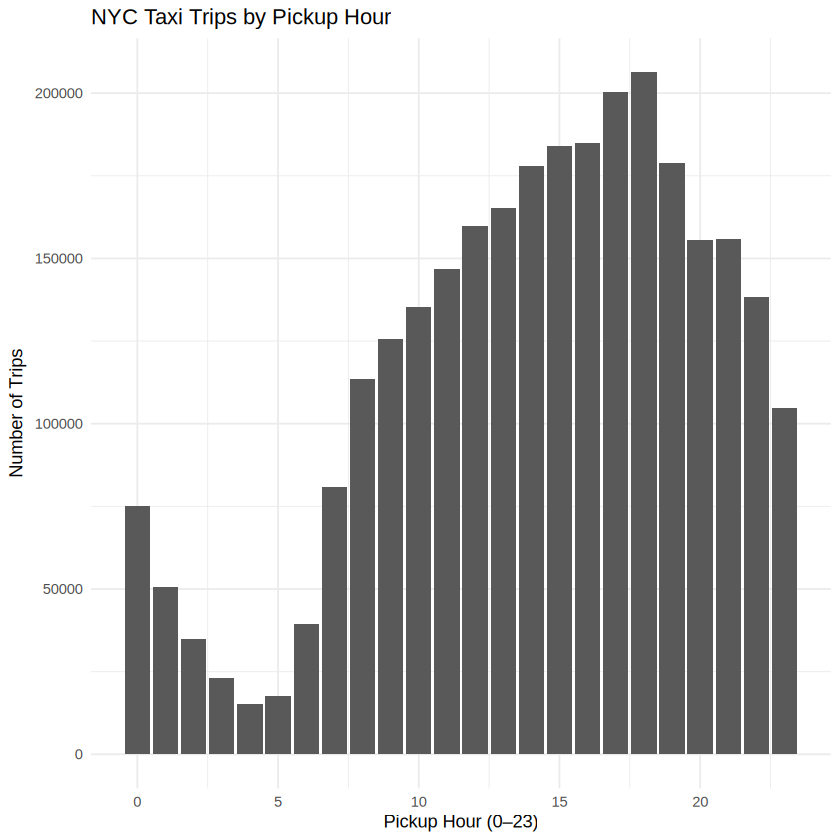

In [14]:

ggplot(
  hourly_demand,
  aes(x = pickup_hour, y = total_trips)
) +
  geom_col() +
  labs(
    title = "NYC Taxi Trips by Pickup Hour",
    x = "Pickup Hour (0–23)",
    y = "Number of Trips"
  ) +
  theme_minimal()


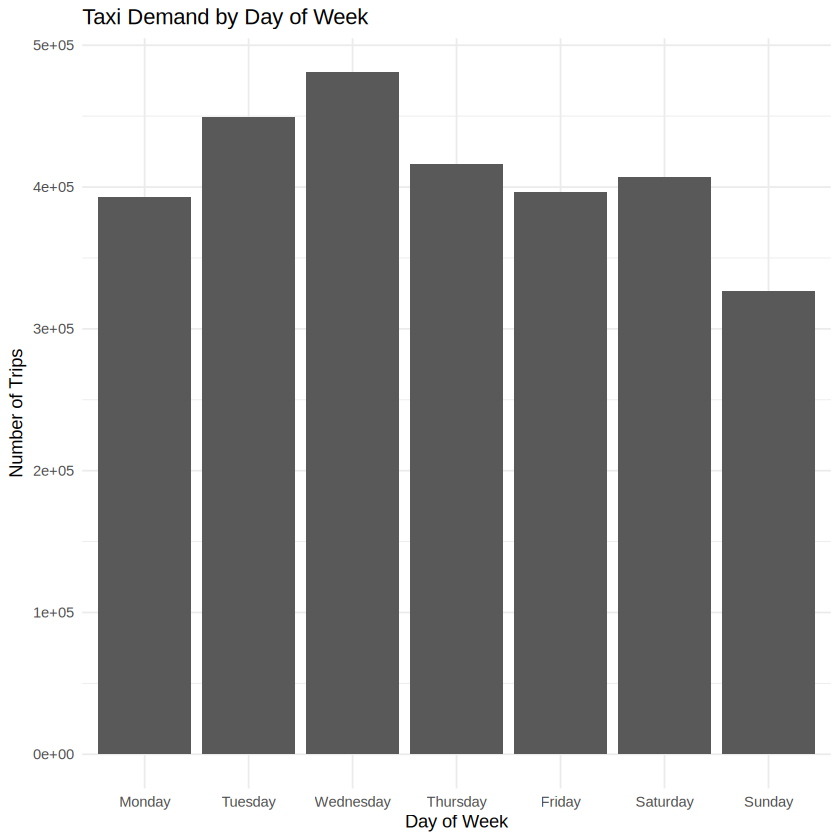

In [15]:

ggplot(
  weekday_demand,
  aes(x = pickup_weekday, y = total_trips)
) +
  geom_col() +
  labs(
    title = "Taxi Demand by Day of Week",
    x = "Day of Week",
    y = "Number of Trips"
  ) +
  theme_minimal()


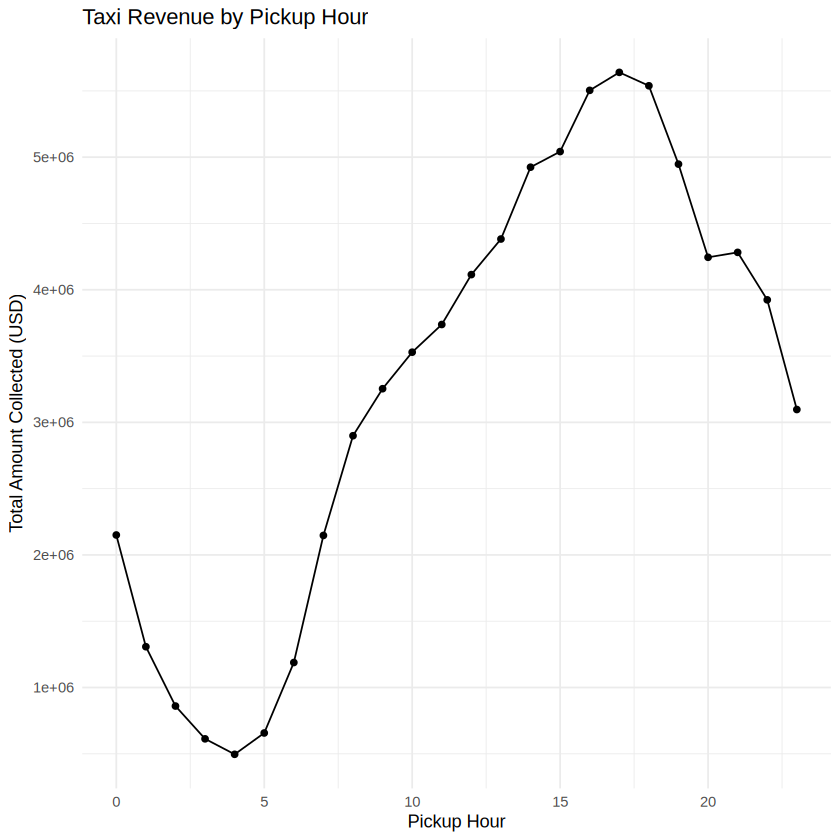

In [16]:

ggplot(
  hourly_revenue,
  aes(x = pickup_hour, y = total_revenue)
) +
  geom_line() +
  geom_point() +
  labs(
    title = "Taxi Revenue by Pickup Hour",
    x = "Pickup Hour",
    y = "Total Amount Collected (USD)"
  ) +
  theme_minimal()


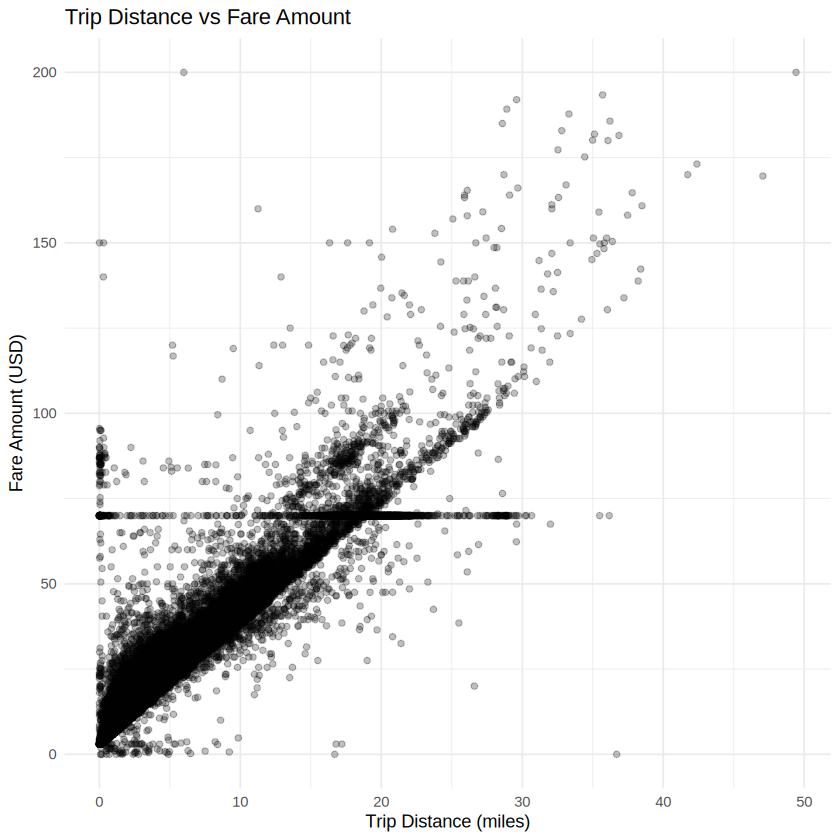

In [17]:

plot_sample <- sample_trips[
  is.finite(trip_distance) &
  is.finite(fare_amount) &
  trip_distance <= 50 &
  fare_amount <= 200
]

ggplot(
  plot_sample,
  aes(x = trip_distance, y = fare_amount)
) +
  geom_point(alpha = 0.25) +
  labs(
    title = "Trip Distance vs Fare Amount",
    x = "Trip Distance (miles)",
    y = "Fare Amount (USD)"
  ) +
  theme_minimal()


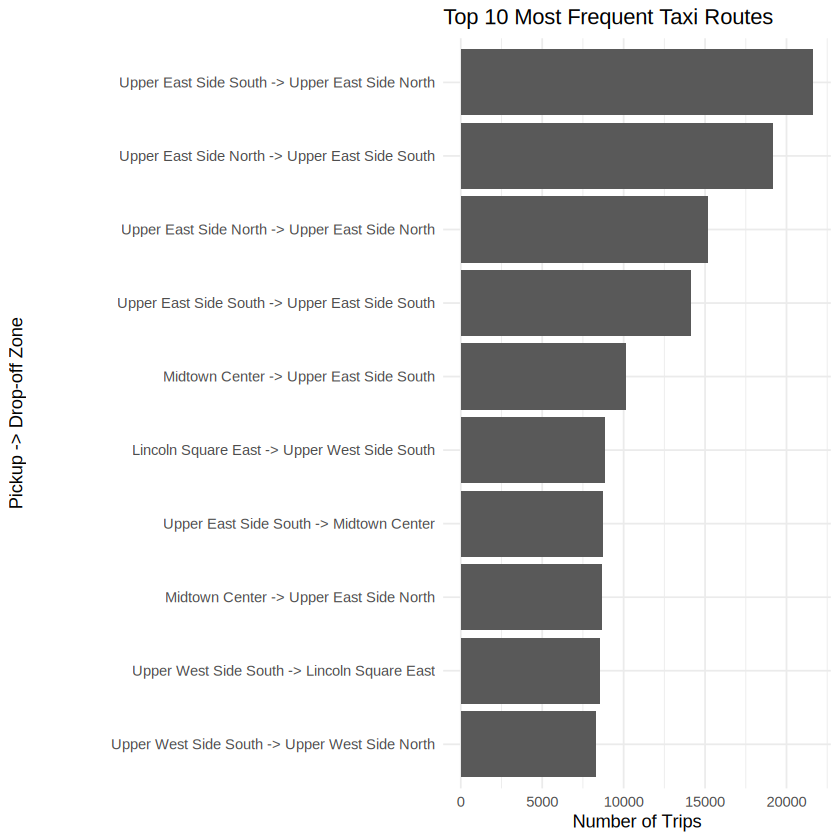

In [18]:

top_routes_plot <- copy(top_routes)

top_routes_plot[, route := paste(
  pickup_zone, "->", dropoff_zone
)]

ggplot(
  top_routes_plot,
  aes(x = reorder(route, total_trips), y = total_trips)
) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Top 10 Most Frequent Taxi Routes",
    x = "Pickup -> Drop-off Zone",
    y = "Number of Trips"
  ) +
  theme_minimal()


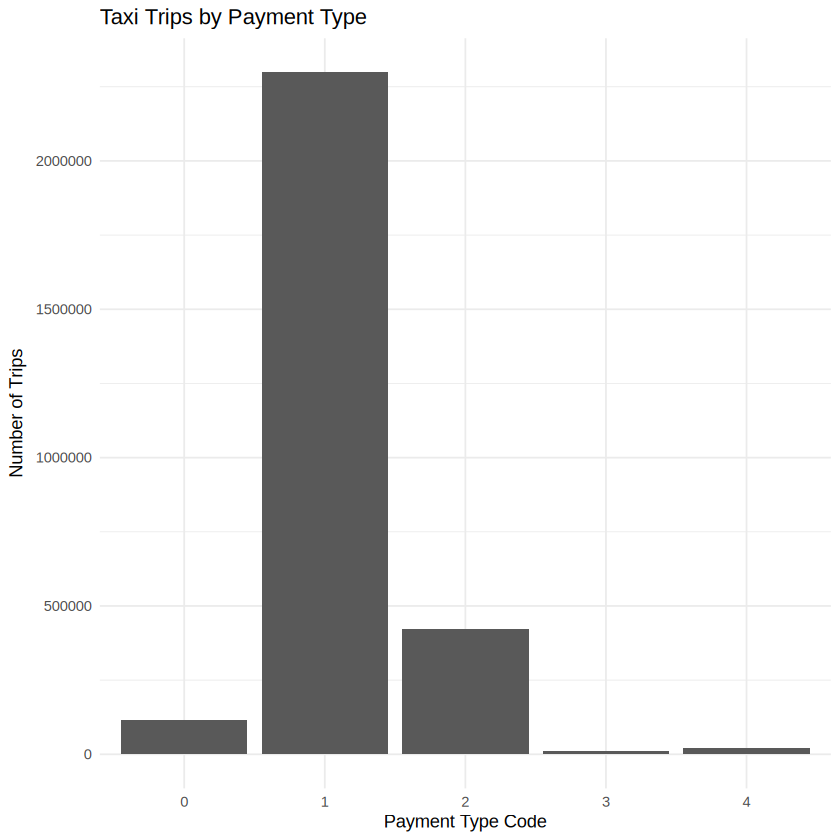

In [19]:

ggplot(
  payment_summary,
  aes(x = factor(payment_type), y = total_trips)
) +
  geom_col() +
  labs(
    title = "Taxi Trips by Payment Type",
    x = "Payment Type Code",
    y = "Number of Trips"
  ) +
  theme_minimal()


In [20]:

cat("========== LAB 8 FINAL SUMMARY ==========\n")

cat("Cleaned records:", nrow(trips), "\n")
cat("Columns after zone joins:", ncol(trips), "\n")

cat("\nMost frequent route:\n")
print(top_routes[1])

cat("\nHighest-revenue route:\n")
print(top_revenue_routes[1])

cat("\nBenchmark results:\n")
print(benchmark_summary)

cat("\nSequential processing time:", seq_time, "seconds\n")
cat("Parallel processing time:", par_time, "seconds\n")
cat("Parallel speedup:", speedup, "\n")

cat("\nLab 8 completed!\n")


========== LAB 8 FINAL SUMMARY ==========
Cleaned records: 2870052 
Columns after zone joins: 21 

Most frequent route:
             pickup_zone          dropoff_zone total_trips total_revenue
                  <char>                <char>       <int>         <num>
1: Upper East Side South Upper East Side North       21642      340615.5

Highest-revenue route:
   pickup_zone   dropoff_zone total_trips total_revenue
        <char>         <char>       <int>         <num>
1: JFK Airport Outside of NYC        5832      719586.8

Benchmark results:
         expr      min       lq     mean   median       uq      max neval
       <fctr>    <num>    <num>    <num>    <num>    <num>    <num> <num>
1: Vectorized  722.271  733.907 1066.073  747.801  782.420 2343.967     5
2:     lapply 4200.181 4316.735 5015.445 4619.996 5347.099 6593.212     5
3:      apply 3164.039 3230.347 3829.436 3424.319 3536.289 5792.188     5
4: data_table 2517.197 2533.288 3222.670 2534.587 2725.276 5803.003     5

Sequ